# A Two-Class MLP from Scratch

The classroom demo from Lecture 11, as a notebook. Everything here is NumPy:
a one-hidden-layer network with tanh units, its gradient derived by
backpropagation, and gradient descent on a two-dimensional classification
problem small enough to draw. Because the input has two coordinates we can
draw the decision rule after every update, draw each hidden unit as a
function on the plane, and watch what changes when we change the width, the
learning rate, or the random seed.

The question the notebook answers is the one on the slide: which changes
alter the **function class**, and which alter only the **training path**
within that class?

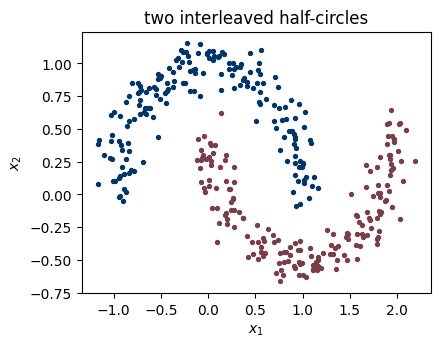

observations: (360, 2)  class balance: 0.5


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 26512
BLUE, RED, GREEN = '#00356B', '#7A3E47', '#5B7864'

def two_moons(n=180, seed=SEED):
    rng = np.random.default_rng(seed)
    angle = rng.uniform(0, np.pi, n)
    upper = np.column_stack([np.cos(angle), np.sin(angle)]) + rng.normal(0, 0.10, (n, 2))
    lower = np.column_stack([1 - np.cos(angle), 0.5 - np.sin(angle)]) + rng.normal(0, 0.10, (n, 2))
    return np.vstack([upper, lower]), np.r_[np.zeros(n), np.ones(n)]

X, y = two_moons()
xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1.2, 1.6, 200))
grid = np.column_stack([xx.ravel(), yy.ravel()])

def draw(ax, probability_on_grid=None, title=''):
    """Scatter the data; optionally shade the grid by predicted class."""
    if probability_on_grid is not None:
        prob = probability_on_grid.reshape(xx.shape)
        ax.contourf(xx, yy, prob, levels=[0, 0.5, 1], colors=['#DCE8F2', '#F4DEE0'])
        ax.contour(xx, yy, prob, levels=[0.5], colors=[GREEN], linewidths=1.5)
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=8, color=BLUE)
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=8, color=RED)
    ax.set(title=title, xlabel='$x_1$', ylabel='$x_2$')

fig, ax = plt.subplots(figsize=(4.5, 3.4))
draw(ax, title='two interleaved half-circles')
plt.show()
print('observations:', X.shape, ' class balance:', y.mean())

## 1. A linear classifier runs out of room

Logistic regression (Lecture 8) fits $p(x)=\sigma(w^\top x+b)$ by gradient
descent on the cross-entropy. Its decision boundary is a line, and no line
separates two interleaved half-circles. The fit below is the best a line can
do: about 88% training accuracy, with the tips of both moons on the wrong
side.

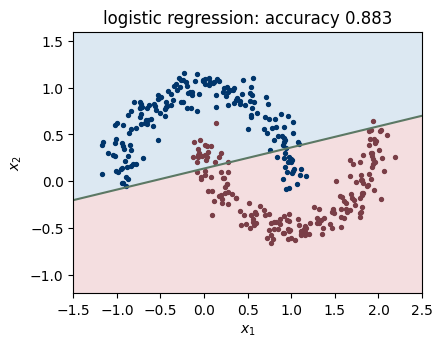

In [2]:
def sigmoid(v):
    return 1 / (1 + np.exp(-np.clip(v, -30, 30)))

def cross_entropy(p, y):
    return -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))

w, b = np.zeros(2), 0.0
for step in range(2000):
    p = sigmoid(X @ w + b)
    gradient = (p - y) / len(y)              # dL/d(score), one entry per observation
    w -= 1.0 * (X.T @ gradient)
    b -= 1.0 * gradient.sum()
linear_accuracy = np.mean((sigmoid(X @ w + b) > 0.5) == y)
fig, ax = plt.subplots(figsize=(4.5, 3.4))
draw(ax, sigmoid(grid @ w + b), title=f'logistic regression: accuracy {linear_accuracy:.3f}')
plt.show()

## 2. The model: one hidden layer of tanh units

With hidden width $m$, the network computes
$$z=W_1^\top x+b_1\in\mathbb R^m,\qquad h=\tanh(z),\qquad
s=w_2^\top h+b_2,\qquad p=\sigma(s).$$
We store $W_1$ as a $2\times m$ array so that a data matrix of shape
$(n,2)$ times $W_1$ gives the $(n,m)$ matrix of hidden values. The
activation is what makes depth count: with the identity in place of
$\tanh$, the two affine maps compose into a single affine map
$x\mapsto (W_1 w_2)^\top x+(b_1^\top w_2+b_2)$, and the model is logistic
regression again. The cell checks that identity numerically.

In [3]:
def initialize(width, seed=SEED):
    local = np.random.default_rng(seed + width)
    return {'W1': local.normal(0, 0.65, (2, width)), 'b1': np.zeros(width),
            'w2': local.normal(0, 0.50, (width, 1)), 'b2': np.zeros(1)}

def forward(params, points, activation=np.tanh):
    Z = points @ params['W1'] + params['b1']
    H = activation(Z)
    S = (H @ params['w2'] + params['b2']).ravel()
    return Z, H, sigmoid(S)

params = initialize(width=8)
_, H, p = forward(params, X)
print('hidden values:', H.shape, ' probabilities:', p.shape)

# Without the activation the network collapses to one affine map.
_, _, p_identity = forward(params, X, activation=lambda z: z)
w_collapsed = params['W1'] @ params['w2']
b_collapsed = params['b1'] @ params['w2'] + params['b2']
assert np.allclose(p_identity, sigmoid((X @ w_collapsed + b_collapsed).ravel()))
print('identity activation = logistic regression with w =', np.round(w_collapsed.ravel(), 3))

hidden values: (360, 8)  probabilities: (360,)
identity activation = logistic regression with w = [ 0.345 -0.059]


## 3. The gradient by backpropagation

The loss is the mean cross-entropy $L=-\frac1n\sum_i\big[y_i\log p_i+(1-y_i)\log(1-p_i)\big]$.
Writing $\overline v=\partial L/\partial v$ and stacking observations as
rows, the local rules from the lecture give, in reverse order,
$$\overline s=\tfrac1n(p-y),\qquad
\overline w_2=H^\top\overline s,\qquad \overline b_2=\mathbf 1^\top\overline s,\qquad
\overline H=\overline s\,w_2^\top,$$
$$\overline Z=\overline H\odot(1-H^2),\qquad
\overline W_1=X^\top\overline Z,\qquad \overline b_1=\mathbf 1^\top\overline Z,$$
using $\tanh'(z)=1-\tanh^2(z)$. Each gradient has the shape of its parameter.
Before trusting these formulas we compare a few coordinates with centered
finite differences of the loss.

In [4]:
def loss_and_gradients(params, X, y):
    Z, H, p = forward(params, X)
    s_bar = ((p - y) / len(y))[:, None]
    H_bar = s_bar @ params['w2'].T
    Z_bar = H_bar * (1 - H ** 2)
    gradients = {'w2': H.T @ s_bar, 'b2': s_bar.sum(0),
                 'W1': X.T @ Z_bar, 'b1': Z_bar.sum(0)}
    return cross_entropy(p, y), gradients

loss, gradients = loss_and_gradients(params, X, y)
rows = []
for name, index in [('W1', (0, 3)), ('W1', (1, 5)), ('b1', (2,)), ('w2', (4, 0)), ('b2', (0,))]:
    epsilon = 1e-6
    plus = {k: v.copy() for k, v in params.items()}; plus[name][index] += epsilon
    minus = {k: v.copy() for k, v in params.items()}; minus[name][index] -= epsilon
    numeric = (loss_and_gradients(plus, X, y)[0] - loss_and_gradients(minus, X, y)[0]) / (2 * epsilon)
    rows.append({'coordinate': f'{name}{index}', 'backprop': gradients[name][index],
                 'finite difference': numeric,
                 'relative error': abs(gradients[name][index] - numeric) / abs(numeric)})
display(pd.DataFrame(rows))
assert all(r['relative error'] < 1e-6 for r in rows)

,coordinate,backprop,finite difference,relative error
0,"W1(0, 3)",-0.011411,-0.011411,2.255666e-11
1,"W1(1, 5)",-0.007986,-0.007986,5.695805e-09
2,"b1(2,)",-0.000078,-0.000078,3.602936e-07
3,"w2(4, 0)",-0.143807,-0.143807,8.373817e-11
4,"b2(0,)",0.028500,0.028500,1.153210e-09


## 4. Watch the boundary move

Full-batch gradient descent, $\theta\leftarrow\theta-\eta\nabla L(\theta)$,
with all 360 observations in every update. The function `train` returns the
parameters at the requested update counts so that we can draw the decision
rule at four moments. At update 0 the boundary is wherever the random
initialization put it; by update 800 it has bent around both moons.

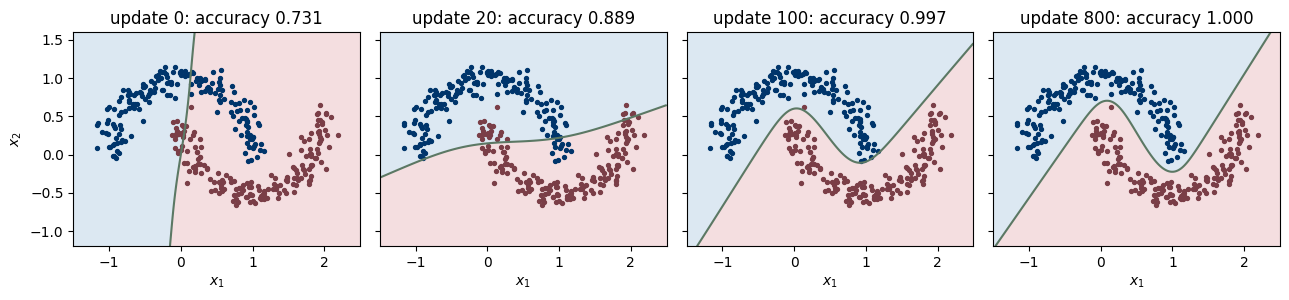

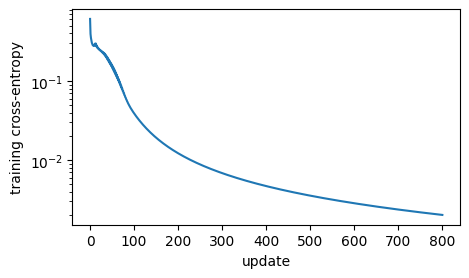

In [5]:
def train(width=8, rate=3.0, steps=800, seed=SEED, snapshots=()):
    params = initialize(width, seed)
    losses, saved = [], {}
    for t in range(steps + 1):
        if t in snapshots:
            saved[t] = {k: v.copy() for k, v in params.items()}
        loss, gradients = loss_and_gradients(params, X, y)
        losses.append(loss)
        if t == steps:
            break
        for name in params:
            params[name] -= rate * gradients[name]
    return params, np.array(losses), saved

params, losses, saved = train(snapshots=(0, 20, 100, 800))
fig, axes = plt.subplots(1, 4, figsize=(13, 3.1), sharey=True)
for ax, (t, snapshot) in zip(axes, saved.items()):
    accuracy = np.mean((forward(snapshot, X)[2] > 0.5) == y)
    draw(ax, forward(snapshot, grid)[2], title=f'update {t}: accuracy {accuracy:.3f}')
    ax.set_ylabel('$x_2$' if t == 0 else '')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(losses)
ax.set(xlabel='update', ylabel='training cross-entropy', yscale='log')
plt.show()

## 5. Hidden units are learned features

Hidden unit $j$ computes $h_j(x)=\tanh(W_{1,\cdot j}^\top x+b_{1j})$, a
smooth step across a line in the plane. Its contribution to the output
score is $w_{2j}h_j(x)$, and the network adds all eight contributions:
$$s(x)=\sum_{j=1}^{8}w_{2j}h_j(x)+b_2.$$
Each panel shades one hidden unit's value. The green curve is the **same
final decision boundary** overlaid on every panel; it is not that unit's
own boundary. The printed output weight shows whether the unit's pattern
adds to or subtracts from the score. Together the learned steps form the
curved predictor, even though no single unit traces both moons. Gradient
descent learns both where each step lies and how much it contributes.

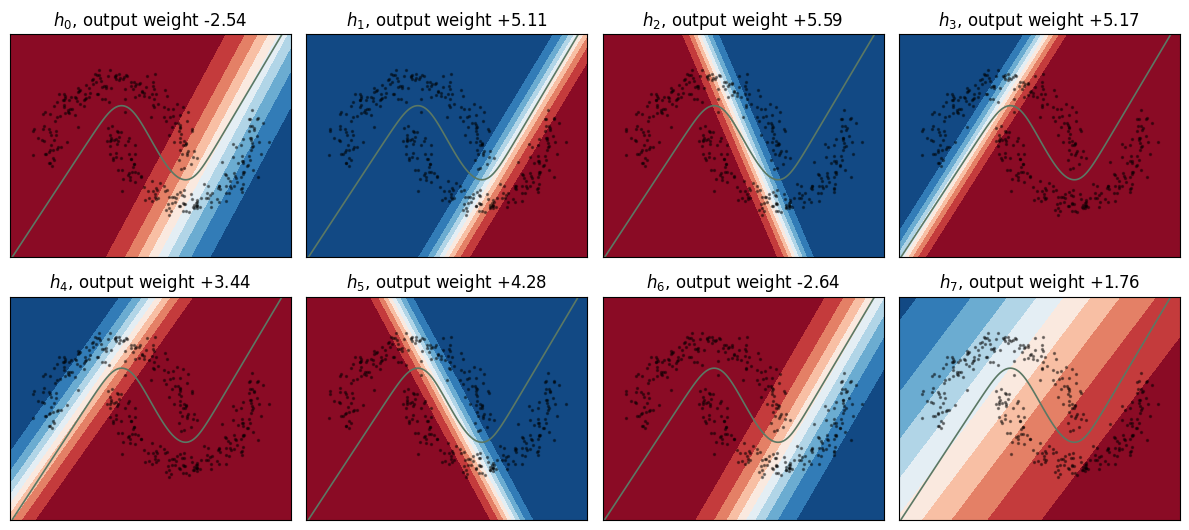

In [6]:
def draw_hidden_units(params, axes, boundary=True):
    _, H_grid, p_grid = forward(params, grid)
    for j, ax in enumerate(axes):
        ax.contourf(xx, yy, H_grid[:, j].reshape(xx.shape), levels=np.linspace(-1, 1, 11), cmap='RdBu_r')
        if boundary:
            ax.contour(xx, yy, p_grid.reshape(xx.shape), levels=[0.5], colors=[GREEN], linewidths=1.2)
        ax.scatter(X[:, 0], X[:, 1], s=2, color='black', alpha=0.4)
        ax.set(title=f'$h_{j}$, output weight {params["w2"][j, 0]:+.2f}', xticks=[], yticks=[])

fig, axes = plt.subplots(2, 4, figsize=(12, 5.4))
draw_hidden_units(params, axes.ravel())
plt.tight_layout(); plt.show()

## 6. Width changes the function class

Train the same way at widths 1, 2, 4, 8, and 32. A width-one network is
$\sigma(w_2\tanh(w_1^\top x+b_1)+b_2)$, a monotone function of the linear
score $w_1^\top x+b_1$, so any decision boundary it has is a line. With
two or more units, sums of tanh features can produce curved boundaries;
there is no general "one bend per unit" rule. In this particular run,
widths one and two fit nearly straight boundaries and miss part of the
pattern, while widths four, eight, and thirty-two fit curves that separate
the moons.

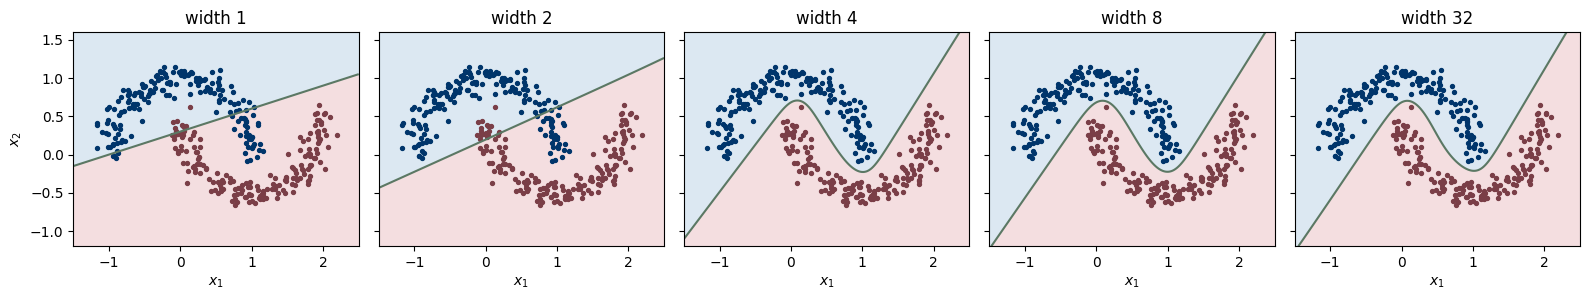

,parameters,final loss,training accuracy
width,,,
1,5,0.302,0.875
2,9,0.230,0.856
4,17,0.003,1.000
8,33,0.002,1.000
32,129,0.003,1.000


In [7]:
widths = [1, 2, 4, 8, 32]
fig, axes = plt.subplots(1, len(widths), figsize=(16, 3.1), sharey=True)
rows = []
for ax, width in zip(axes, widths):
    fitted, losses_w, _ = train(width=width)
    accuracy = np.mean((forward(fitted, X)[2] > 0.5) == y)
    rows.append({'width': width, 'parameters': 4 * width + 1,
                 'final loss': losses_w[-1], 'training accuracy': accuracy})
    draw(ax, forward(fitted, grid)[2], title=f'width {width}')
    ax.set_ylabel('$x_2$' if width == 1 else '')
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index('width').round(3))

## 7. The learning rate changes the training path

Hold the width at eight and the initialization fixed; change only $\eta$.
A small rate makes slow, steady progress. A rate near the edge of stability
oscillates before it settles. Past that edge the loss jumps around and can
grow, because each step overshoots the valley it is descending. None of
these runs changes what the network *could* represent; they change which
member of the class the optimizer reaches, and whether it reaches one at
all.

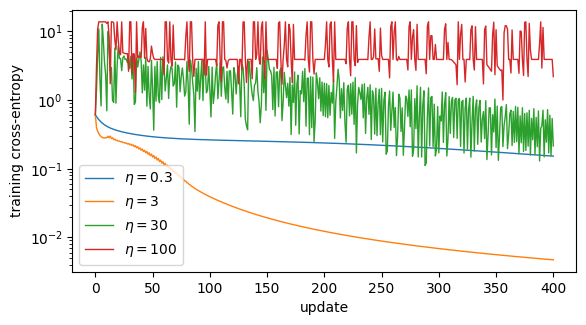

,final loss,largest loss after update 100,training accuracy
learning rate,,,
0.3,0.152,0.262,0.947
3.0,0.005,0.039,1.000
30.0,0.214,5.215,0.931
100.0,2.193,13.771,0.858


In [8]:
rates = [0.3, 3.0, 30.0, 100.0]
fig, ax = plt.subplots(figsize=(6.5, 3.4))
rows = []
for rate in rates:
    fitted, losses_r, _ = train(rate=rate, steps=400)
    ax.plot(losses_r, lw=1, label=f'$\\eta={rate:g}$')
    rows.append({'learning rate': rate, 'final loss': losses_r[-1],
                 'largest loss after update 100': losses_r[100:].max(),
                 'training accuracy': np.mean((forward(fitted, X)[2] > 0.5) == y)})
ax.set(xlabel='update', ylabel='training cross-entropy', yscale='log')
ax.legend()
plt.show()
display(pd.DataFrame(rows).set_index('learning rate').round(3))

## 8. The seed changes the representation

Two runs with the same width, rate, and data, differing only in the random
initialization, both separate the moons. Their hidden units are different
functions: the steps sit in different places and carry different output
weights. The network's representation is one of many that work, and which
one you get is an accident of the starting point.

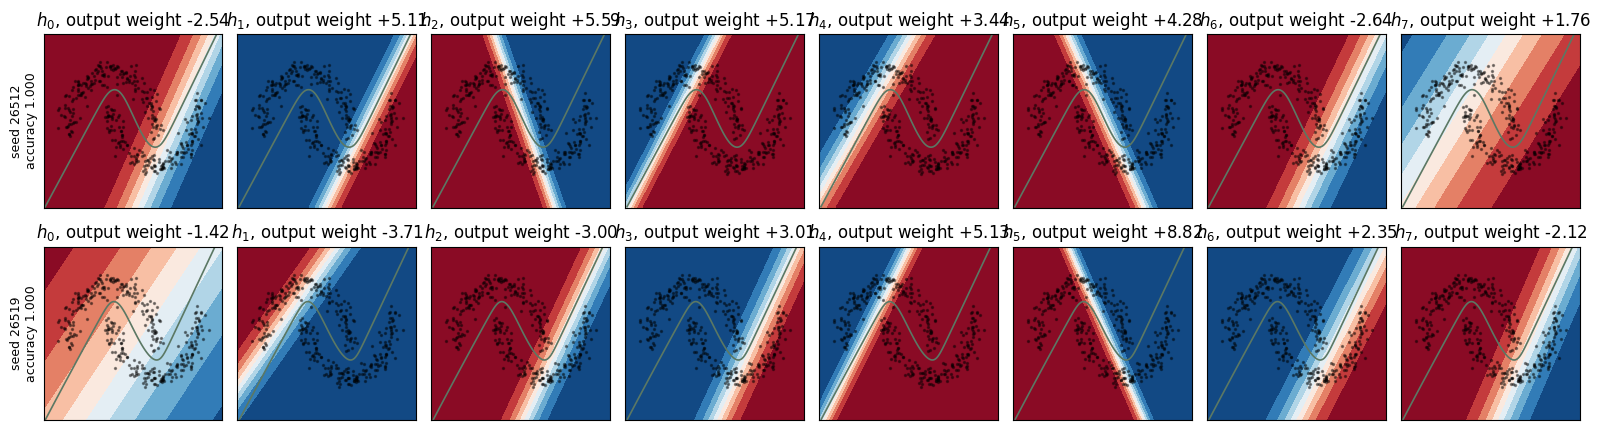

In [9]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for row, seed in enumerate([SEED, SEED + 7]):
    fitted, _, _ = train(seed=seed)
    accuracy = np.mean((forward(fitted, X)[2] > 0.5) == y)
    draw_hidden_units(fitted, axes[row])
    axes[row, 0].set_ylabel(f'seed {seed}\naccuracy {accuracy:.3f}', fontsize=9)
plt.tight_layout(); plt.show()

## 9. Random boundaries before training

Each panel uses randomly initialized parameters; the labels were not used
to choose them. The width-two draws look almost like straight lines. This
is common at this initialization scale: with zero biases and modest hidden
scores, $\tanh(z)\approx z$, so the network score is approximately
$s(x)\approx (W_1w_2)^\top x$. A width-two tanh network can also make a
nonlinear boundary; these six draws do not describe its full function
class. Some width-thirty-two draws curve more, but none follows the moons
well. Training moves through the class to find useful parameters.

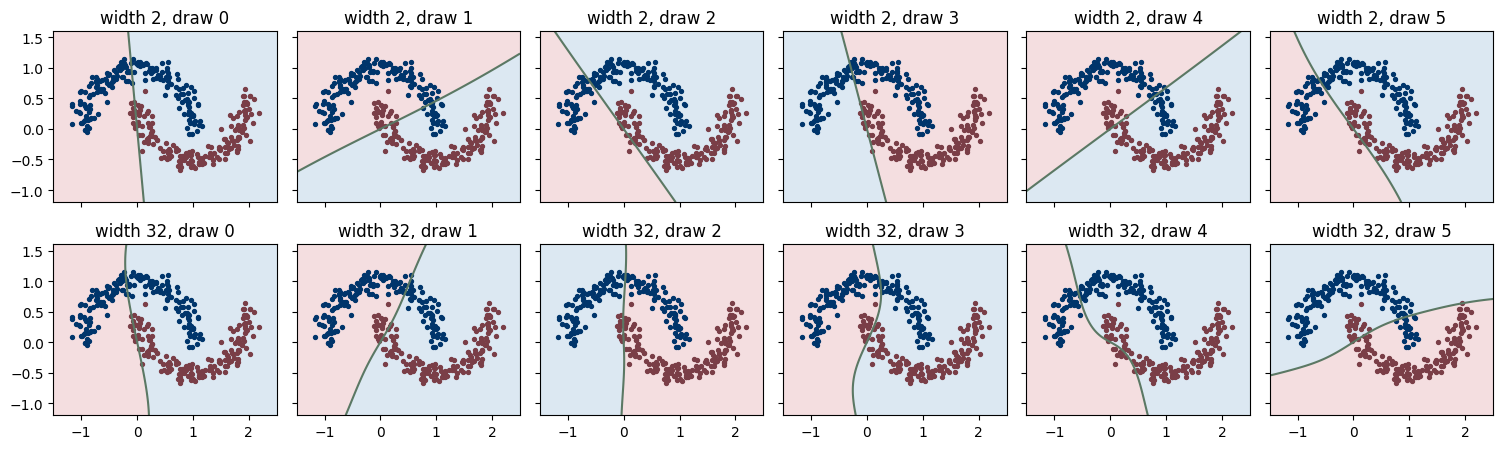

In [10]:
fig, axes = plt.subplots(2, 6, figsize=(15, 4.6), sharex=True, sharey=True)
for row, width in enumerate([2, 32]):
    for col in range(6):
        random_params = initialize(width, seed=1000 * width + col)
        draw(axes[row, col], forward(random_params, grid)[2], title=f'width {width}, draw {col}')
        axes[row, col].set(xlabel='', ylabel='')
plt.tight_layout(); plt.show()

## Summary

Width and the activation function decide the **function class**: a
width-one tanh network has a straight decision boundary when it has one,
while additional units can combine to make curved boundaries. Replacing
tanh with the identity collapses any width to logistic regression. The
learning rate, the number of updates, and the random seed affect the
**training path** through that class: too large a rate fails to settle,
too few updates stop early, and different seeds can reach different useful
representations.